# **Video Checking**

In [ ]:
!pip install -q ultralytics albumentations

In [ ]:
import torch, cv2, ultralytics
print("GPU:", torch.cuda.is_available(), "| cv2:", cv2.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: True | cv2: 4.14.0


In [ ]:
# 2. Re-run the mount command
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
VIDEO = "/content/drive/MyDrive/staff_detection/copy_sample_video.mp4"

In [ ]:
from ultralytics import YOLO
model = YOLO("yolo11m.pt")

In [ ]:

model.track(source=VIDEO, classes=[0], tracker="botsort.yaml",
            conf=0.25, imgsz=960, save=True, project="/content/drive/MyDrive/staff_detection/runs", name="person_test")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 182ms
Prepared 1 package in 51ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1341) /content/drive/MyDrive/staff_detection/copy_sample_video.mp4: 736x960 (no det

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

In [ ]:
import cv2, os
BASE  = "/content/drive/MyDrive/staff_detection"
VIDEO = f"{BASE}/copy_sample_video.mp4"
OUT   = f"{BASE}/to_label"; os.makedirs(OUT, exist_ok=True)

WINDOWS = [(15.2,15.7),(16.9,17.5),(18.4,18.9),(20.3,20.5),(21.9,22.4),
           (32.4,32.8),(33.9,34.7),(35.7,36.2),(37.0,37.8),(38.9,39.4),
           (40.6,41.2),(42.4,43.0),(44.3,44.9),(46.2,46.8),(48.0,48.6)]
M = 0.3

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
saved = 0
for i in range(n):
    ok, f = cap.read()
    if not ok: break
    t = i / fps
    in_win = any(a-M <= t <= b+M for a, b in WINDOWS)
    if (in_win and i % 2 == 0) or (not in_win and i % 15 == 0):
        tag = "pos" if in_win else "neg"
        cv2.imwrite(f"{OUT}/{tag}_t{t:06.2f}_f{i:06d}.jpg", f)   # time and frame number in the name
        saved += 1
print("fps:", fps, "| saved:", saved)

fps: 25.0 | saved: 280


# **Connect to Roboflow, Import Labelled Image**


In [ ]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 127.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [ ]:

from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("").project("staff-name-tag-detection")
version = project.version(1)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Staff-Name-Tag-Detection-1 in yolov11:: 100%|██████████| 368/368 [00:00<00:00, 6843.32it/s]


In [ ]:
import glob, os
DS = "/content/Staff-Name-Tag-Detection-1"
print(open(f"{DS}/data.yaml").read())

labs = glob.glob(f"{DS}/train/labels/*.txt")
nonempty = [f for f in labs if os.path.getsize(f) > 0]
print("label files:", len(labs), "| with boxes:", len(nonempty), "| empty (negatives):", len(labs)-len(nonempty))

classes = set()
for f in nonempty:
    for line in open(f):
        classes.add(line.split()[0])
print("class ids used:", classes)      # you want only {'0'}

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['name_tag']

roboflow:
  workspace: lees-workspace-wogji
  project: staff-name-tag-detection
  version: 1
  license: Private
  url: https://app.roboflow.com/lees-workspace-wogji/staff-name-tag-detection/1
label files: 183 | with boxes: 122 | empty (negatives): 61
class ids used: {'0'}


#**Split data into train, valid and test**

In [ ]:
import glob, os, re, shutil

SRC = "/content/Staff-Name-Tag-Detection-1"
DST = "/content/data"

VALID_W = [(38.9,39.4),(40.6,41.2),(42.4,43.0)]
TEST_W  = [(44.3,44.9),(46.2,46.8),(48.0,48.6)]
M = 0.3

def get_time(name):
    m = re.search(r"_t(\d+)[-.](\d+)_f(\d+)", name)
    return float(f"{m.group(1)}.{m.group(2)}") if m else None

def which(t):
    if t is None: return "train"
    for s, wins in [("valid", VALID_W), ("test", TEST_W)]:
        if any(a-M <= t <= b+M for a, b in wins): return s
    return "train"

for s in ["train", "valid", "test"]:
    os.makedirs(f"{DST}/{s}/images", exist_ok=True)
    os.makedirs(f"{DST}/{s}/labels", exist_ok=True)

counts = {"train": 0, "valid": 0, "test": 0}; unparsed = []
for img in glob.glob(f"{SRC}/train/images/*.jpg"):
    t = get_time(os.path.basename(img))
    if t is None: unparsed.append(os.path.basename(img))
    s = which(t)
    lab = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    shutil.copy(img, f"{DST}/{s}/images/")
    if os.path.exists(lab): shutil.copy(lab, f"{DST}/{s}/labels/")
    counts[s] += 1
print(counts); print("no time found:", unparsed)

{'train': 128, 'valid': 27, 'test': 28}
no time found: ['Screenshot-2026-11-15-122133_png.rf.3856bda499f223f8c06157c6496c0c11.jpg']


In [ ]:
import cv2, numpy as np
ws, hs = [], []
for f in glob.glob("/content/data/train/labels/*.txt"):
    img = cv2.imread(f.replace("labels", "images").replace(".txt", ".jpg"))
    if img is None: continue
    H, W = img.shape[:2]
    for line in open(f):
        _, xc, yc, w, h = map(float, line.split())
        ws.append(w*W); hs.append(h*H)
print("frame size:", W, "x", H)
print("tag width px  5%/50%/95%:", np.percentile(ws, [5, 50, 95]).round(1))
print("tag height px 5%/50%/95%:", np.percentile(hs, [5, 50, 95]).round(1))

frame size: 960 x 720
tag width px  5%/50%/95%: [11.  17.  22.5]
tag height px 5%/50%/95%: [ 6.6 11.  14.9]


In [ ]:
import cv2, numpy as np, random, os, glob, shutil
from ultralytics import YOLO


In [ ]:
# ================= SETTINGS =================
BASE  = "/content/drive/MyDrive/staff_detection"
VIDEO = f"{BASE}/copy_sample_video.mp4"
DATA  = "/content/data"                 # your split folder (train/valid/test)
TAG_W_RANGE = (8, 32)                   # from your measured 11/17/22.5 px
TRAIN_END_S = 37.8                      # backgrounds only before this (valid/test stay unseen)
VARIANTS    = 3                         # synthetic images per background frame
STEP        = 3                         # use every 3rd frame

WINDOWS = [(15.2,15.7),(16.9,17.5),(18.4,18.9),(20.3,20.5),(21.9,22.4),
           (32.4,32.8),(33.9,34.7),(35.7,36.2),(37.0,37.8),(38.9,39.4),
           (40.6,41.2),(42.4,43.0),(44.3,44.9),(46.2,46.8),(48.0,48.6)]
MARGIN = 0.3                            # skip frames where the REAL tag is visible

IMG_DIR = f"{DATA}/train/images"
LAB_DIR = f"{DATA}/train/labels"
os.makedirs(IMG_DIR, exist_ok=True); os.makedirs(LAB_DIR, exist_ok=True)

# remove old synthetic files so re-running doesn't duplicate
for f in glob.glob(f"{IMG_DIR}/syn_*") + glob.glob(f"{LAB_DIR}/syn_*"):
    os.remove(f)


# **Categorized Cropped Name Tag**

In [ ]:
# ================= TAG LIBRARY (RGBA cut-outs) =================
LIB = {}
for kind in ["clear", "mild", "heavy"]:
    imgs = [cv2.imread(f, cv2.IMREAD_UNCHANGED) for f in glob.glob(f"{BASE}/tags/{kind}/*.png")]
    LIB[kind] = [t for t in imgs if t is not None and t.ndim == 3 and t.shape[2] == 4]
print("tags loaded:", {k: len(v) for k, v in LIB.items()})

SOURCE_W = {"clear": 0.25, "mild": 0.20, "heavy": 0.55}
# tags are tiny (8-32 px), so no level-3 blur
BLUR_POLICY  = {"clear": ([0, 1, 2], [2, 3, 3]), "mild": ([0, 1, 2], [3, 3, 1]), "heavy": ([0], [1])}
PERSP_JITTER = {"clear": 0.12, "mild": 0.08, "heavy": 0.04}

tags loaded: {'clear': 2, 'mild': 2, 'heavy': 8}


In [ ]:
# ================= BLUR UTILS =================
def motion_kernel(k, angle):
  ker = np.zeros((k, k), np.float32)
  ker[k // 2, :] = 1
  M = cv2.getRotationMatrix2D((k / 2 - 0.5, k / 2 - 0.5), angle, 1)
  ker = cv2.warpAffine(ker, M, (k, k))
  return ker / max(ker.sum(), 1e-6)


def degrade(roi, level):
  if level == 0:
    return roi
  h, w = roi.shape[:2]
  if level == 1:
    return cv2.GaussianBlur(roi, (3, 3), 0)
  if random.random() < 0.5:
    return cv2.filter2D(
        roi,
        -1,
        motion_kernel(random.choice([3, 5, 7]), random.uniform(0, 180)),
    )
  small = cv2.resize(roi, (max(2, int(w * 0.6)), max(2, int(h * 0.6))))
  return cv2.resize(small, (w, h))

In [ ]:
# ================= TAG TRANSFORM =================
def make_tag_patch(tag, width_px, kind):
  h, w = tag.shape[:2]
  s = width_px / w
  t = cv2.resize(tag, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
  th, tw = t.shape[:2]
  if th < 3 or tw < 3:
    return None
  pad = int(max(th, tw) * 0.6) + 2
  t = cv2.copyMakeBorder(t, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(0, 0, 0, 0))
  H, W = t.shape[:2]
  j = PERSP_JITTER[kind] * min(tw, th)
  src = np.float32([[pad, pad], [pad + tw, pad], [pad + tw, pad + th], [pad, pad + th]])
  dst = src + np.random.uniform(-j, j, src.shape).astype(np.float32)
  t = cv2.warpPerspective(t, cv2.getPerspectiveTransform(src, dst), (W, H))
  M = cv2.getRotationMatrix2D((W / 2, H / 2), random.uniform(0, 360), 1.0)
  t = cv2.warpAffine(t, M, (W, H))
  rgb = (
      t[..., :3].astype(np.float32) * random.uniform(0.6, 1.3)
      + random.uniform(-25, 25)
  )
  t[..., :3] = np.clip(rgb, 0, 255).astype(np.uint8)
  return t

In [ ]:
# ================= BODY CORE MASKS =================
seg_model = YOLO("yolo11m-seg.pt")


def get_person_masks(frame):
  H, W = frame.shape[:2]
  res = seg_model(
      frame, classes=[0], conf=0.25, imgsz=960, verbose=False
  )[0]
  out = []
  if res.masks is None:
    return out
  for poly in res.masks.xy:
    full = np.zeros((H, W), np.uint8)
    cv2.fillPoly(full, [poly.astype(np.int32)], 1)
    # Distance transform finds pixels deep inside the body, away from edges/arms
    dist = cv2.distanceTransform(full, cv2.DIST_L2, 3)
    if dist.max() < 4:
      continue
    core = (dist >= 0.55 * dist.max()).astype(
        np.uint8
    )  # deepest 45% = core/torso/back
    out.append((full, core))
  return out

In [ ]:
# ================= PASTE ONE TAG (CORE SAMPLING) =================
MIN_ON_PERSON = 0.85


def synth(frame, masks, motion):
  H, W = frame.shape[:2]
  kind = random.choices(list(SOURCE_W), weights=list(SOURCE_W.values()))[0]
  if not LIB[kind]:
    return None
  tag = random.choice(LIB[kind])
  patch = make_tag_patch(tag, random.randint(*TAG_W_RANGE), kind)
  if patch is None:
    return None
  ph, pw = patch.shape[:2]

  # Favor moving people using motion weights
  weights_list = [0.15 + (motion[f > 0].mean() * 10) for f, c in masks]
  full, core = random.choices(masks, weights=weights_list)[0]

  # Sample specifically from the body core (torso/back), avoiding hands/edges
  ys_m, xs_m = np.nonzero(core)
  if len(xs_m) == 0:
    return None
  k = random.randrange(len(xs_m))
  cx, cy = xs_m[k], ys_m[k]
  px, py = int(cx - pw / 2), int(cy - ph / 2)
  if px < 0 or py < 0 or px + pw > W or py + ph > H:
    return None

  fp = patch[..., 3] > 40
  if fp.sum() == 0:
    return None
  on_person = (full[py : py + ph, px : px + pw][fp] > 0).mean()
  if on_person < MIN_ON_PERSON:
    return None

  alpha = (
      cv2.GaussianBlur(patch[..., 3], (3, 3), 0).astype(np.float32)[..., None]
      / 255
  )
  out = frame.copy()
  roi = out[py : py + ph, px : px + pw].astype(np.float32)
  out[py : py + ph, px : px + pw] = (
      patch[..., :3] * alpha + roi * (1 - alpha)
  ).astype(np.uint8)

  ys, xs = np.where(fp)
  bx1, by1, bx2, by2 = px + xs.min(), py + ys.min(), px + xs.max(), py + ys.max()
  if (bx2 - bx1) < 4 or (by2 - by1) < 3:
    return None

  levels, weights = BLUR_POLICY[kind]
  level = random.choices(levels, weights=weights)[0]
  m = 3
  ry1, ry2, rx1, rx2 = (
      max(0, by1 - m),
      min(H, by2 + m),
      max(0, bx1 - m),
      min(W, bx2 + m),
  )
  out[ry1:ry2, rx1:rx2] = degrade(out[ry1:ry2, rx1:rx2], level)

  return (
      out,
      f"0 {(bx1+bx2)/2/W:.6f} {(by1+by2)/2/H:.6f} {(bx2-bx1)/W:.6f} {(by2-by1)/H:.6f}",
  )

In [ ]:
# ================= RUN OVER TRAIN PART OF VIDEO =================
for f in glob.glob(f"{IMG_DIR}/syn_*") + glob.glob(f"{LAB_DIR}/syn_*"):
  os.path.remove(f)

cap = cv2.VideoCapture(VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS)
SKIP = [(a - MARGIN, b + MARGIN) for a, b in WINDOWS]
saved, no_person, i = 0, 0, -1
prev = None

while True:
  ok, frame = cap.read()
  if not ok:
    break
  i += 1
  t = i / FPS

  # Track motion continuously across all frames (even skipped ones)
  gray = cv2.GaussianBlur(
      cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (5, 5), 0
  )
  motion = (
      np.zeros_like(gray)
      if prev is None
      else (cv2.absdiff(gray, prev) > 18).astype(np.uint8)
  )
  prev = gray

  if t >= TRAIN_END_S:
    break
  if i % STEP:
    continue
  if any(a <= t <= b for a, b in SKIP):
    continue

  masks = get_person_masks(frame)
  if not masks:
    no_person += 1
    continue

  made = 0
  for _ in range(VARIANTS * 4):
    if made >= VARIANTS:
      break
    r = synth(frame, masks, motion)
    if r is None:
      continue
    img, label = r
    name = f"syn_{i:06d}_{saved}"
    cv2.imwrite(f"{IMG_DIR}/{name}.jpg", img)
    open(f"{LAB_DIR}/{name}.txt", "w").write(label)
    saved += 1
    made += 1

print(
    f"synthetic images saved: {saved} | frames with no person found: {no_person}"
)

# Backup to Drive
os.makedirs(f"{BASE}/synth_backup", exist_ok=True)
for f in glob.glob(f"{IMG_DIR}/syn_*"):
  shutil.copy(f, f"{BASE}/synth_backup/")

synthetic images saved: 687 | frames with no person found: 2


# **Synthetic Image Checking**
Before

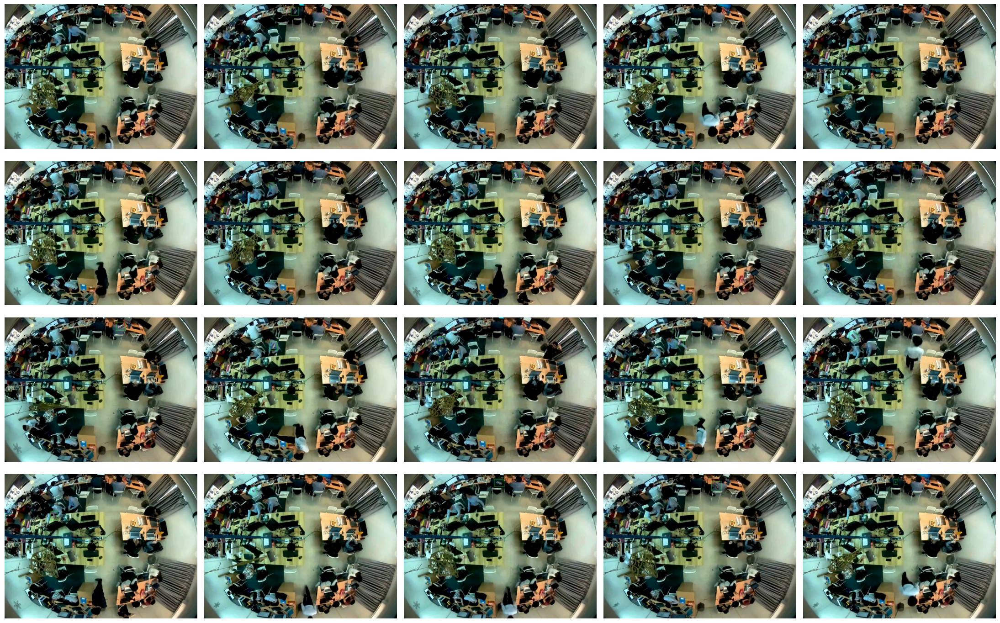

In [ ]:
import matplotlib.pyplot as plt, random, glob, cv2
IMG_DIR = "/content/data/train/images"
files = random.sample(glob.glob(f"{IMG_DIR}/syn_*.jpg"), 20)
fig, ax = plt.subplots(4, 5, figsize=(22, 14))
for a, f in zip(ax.ravel(), files):
    img = cv2.imread(f); H, W = img.shape[:2]
    for l in open(f.replace("images", "labels").replace(".jpg", ".txt")):
        _, xc, yc, w, h = map(float, l.split())
        cv2.rectangle(img, (int((xc-w/2)*W)-8, int((yc-h/2)*H)-8),
                           (int((xc+w/2)*W)+8, int((yc+h/2)*H)+8), (0, 255, 0), 1)
    a.imshow(img[..., ::-1]); a.axis("off")
plt.tight_layout(); plt.show()

After

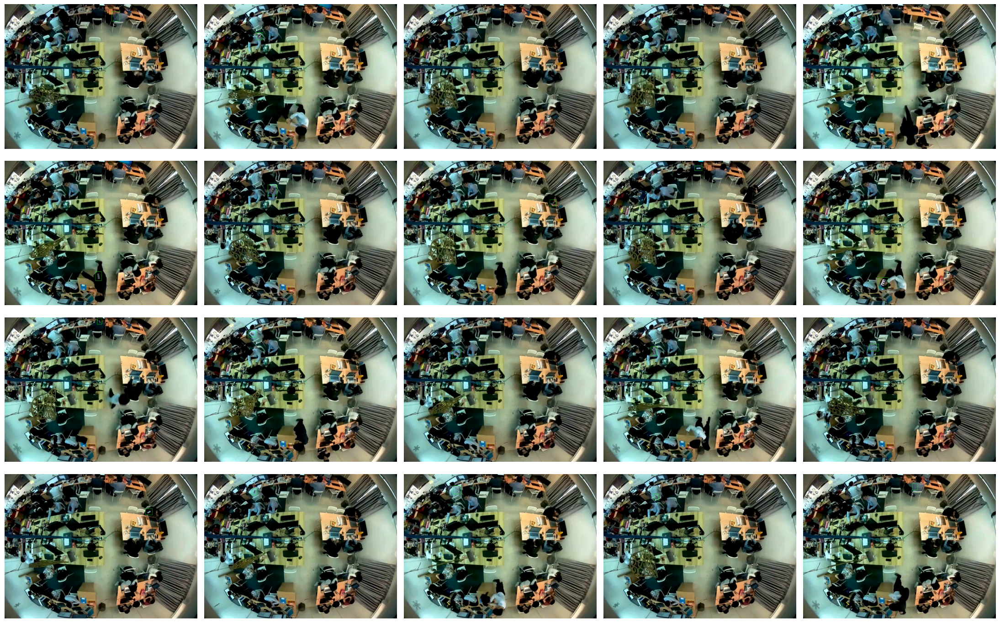

In [ ]:
import matplotlib.pyplot as plt, random, glob, cv2
IMG_DIR = "/content/data/train/images"
files = random.sample(glob.glob(f"{IMG_DIR}/syn_*.jpg"), 20)
fig, ax = plt.subplots(4, 5, figsize=(22, 14))
for a, f in zip(ax.ravel(), files):
    img = cv2.imread(f); H, W = img.shape[:2]
    for l in open(f.replace("images", "labels").replace(".jpg", ".txt")):
        _, xc, yc, w, h = map(float, l.split())
        cv2.rectangle(img, (int((xc-w/2)*W)-8, int((yc-h/2)*H)-8),
                           (int((xc+w/2)*W)+8, int((yc+h/2)*H)+8), (0, 255, 0), 1)
    a.imshow(img[..., ::-1]); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import glob, os
labs = [f for f in glob.glob("/content/data/train/labels/*.txt")
        if "syn_" not in f and "dup" not in f]
nonempty = [f for f in labs if os.path.getsize(f) > 0]
cls = {l.split()[0] for f in nonempty for l in open(f)}
print("real label files:", len(labs), "| with boxes:", len(nonempty),
      "| empty:", len(labs) - len(nonempty), "| classes:", cls)
print(open("/content/Staff-Name-Tag-Detection-1/data.yaml").read())

real label files: 128 | with boxes: 67 | empty: 61 | classes: {'0'}
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['name_tag']

roboflow:
  workspace: lees-workspace-wogji
  project: staff-name-tag-detection
  version: 1
  license: Private
  url: https://app.roboflow.com/lees-workspace-wogji/staff-name-tag-detection/1


In [ ]:
import glob, os, collections

c = collections.Counter()
pos_empty = []
for lab in glob.glob("/content/data/train/labels/*.txt"):
    b = os.path.basename(lab)
    if b.startswith(("syn_", "dup")): continue            # skip synthetic and duplicates
    kind = "pos" if b.startswith("pos_") else "neg" if b.startswith("neg_") else "other"
    has_box = os.path.getsize(lab) > 0
    c[(kind, "box" if has_box else "empty")] += 1
    if kind == "pos" and not has_box:
        pos_empty.append(b)

print(c)
print("pos_ frames with NO box:", len(pos_empty))
print(pos_empty[:20])

Counter({('pos', 'box'): 66, ('neg', 'empty'): 61, ('other', 'box'): 1})
pos_ frames with NO box: 0
[]


In [ ]:
for split in ["valid", "test"]:
    labs = glob.glob(f"/content/data/{split}/labels/*.txt")
    pos = sum(os.path.getsize(f) > 0 for f in labs)
    boxes = sum(len(open(f).read().strip().splitlines()) for f in labs if os.path.getsize(f) > 0)
    print(split, "| images:", len(labs), "| with tag:", pos, "| total boxes:", boxes)

valid | images: 27 | with tag: 27 | total boxes: 27
test | images: 28 | with tag: 28 | total boxes: 28


In [ ]:
import shutil

# delete old duplicates first, so re-running doesn't multiply them again
for f in glob.glob("/content/data/train/images/dup*") + glob.glob("/content/data/train/labels/dup*"):
    os.remove(f)

for img in glob.glob("/content/data/train/images/*.jpg"):
    b = os.path.basename(img)
    if b.startswith("syn_"): continue
    lab = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for k in (1, 2):                                   # 2 extra copies = 3x in total
        shutil.copy(img, f"/content/data/train/images/dup{k}_{b}")
        if os.path.exists(lab):
            shutil.copy(lab, f"/content/data/train/labels/dup{k}_{b.rsplit('.', 1)[0]}.txt")

n_img = len(glob.glob("/content/data/train/images/*.jpg"))
n_syn = len(glob.glob("/content/data/train/images/syn_*.jpg"))
print("train images:", n_img, "| synthetic:", n_syn, "| real (incl. copies):", n_img - n_syn)

train images: 1071 | synthetic: 687 | real (incl. copies): 384


In [ ]:
import glob, os, random, shutil

KEEP = 250
IMG = "/content/data/train/images"
LAB = "/content/data/train/labels"
SPARE = "/content/data/syn_spare"            # not deleted, just moved aside
os.makedirs(f"{SPARE}/images", exist_ok=True)
os.makedirs(f"{SPARE}/labels", exist_ok=True)

syn = sorted(glob.glob(f"{IMG}/syn_*.jpg"))
random.seed(0)                                # same result every run
random.shuffle(syn)
move = syn[KEEP:]                             # everything after the first 250

for img in move:
    b = os.path.basename(img)
    lab = f"{LAB}/{b.rsplit('.', 1)[0]}.txt"
    shutil.move(img, f"{SPARE}/images/{b}")
    if os.path.exists(lab):
        shutil.move(lab, f"{SPARE}/labels/{os.path.basename(lab)}")

n_syn  = len(glob.glob(f"{IMG}/syn_*.jpg"))
n_all  = len(glob.glob(f"{IMG}/*.jpg"))
print("synthetic:", n_syn, "| real incl. copies:", n_all - n_syn,
      "| real share: %.0f%%" % (100 * (n_all - n_syn) / n_all))

synthetic: 250 | real incl. copies: 384 | real share: 61%


In [ ]:
open("/content/data/data.yaml", "w").write("""path: /content/data
train: train/images
val: valid/images
test: test/images
names:
  0: name_tag
""")

97

In [ ]:
for sp in ["train", "valid", "test"]:
    for sub in ["images", "labels"]:
        os.makedirs(f"/content/data_real/{sp}/{sub}", exist_ok=True)

for f in glob.glob("/content/data/train/images/*.jpg"):
    if os.path.basename(f).startswith("syn_"): continue          # leave synthetic out
    shutil.copy(f, "/content/data_real/train/images/")
    l = f.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(l): shutil.copy(l, "/content/data_real/train/labels/")

for sp in ["valid", "test"]:                                     # same valid/test for both runs
    shutil.copytree(f"/content/data/{sp}", f"/content/data_real/{sp}", dirs_exist_ok=True)

open("/content/data_real/data.yaml", "w").write("""path: /content/data_real
train: train/images
val: valid/images
test: test/images
names:
  0: name_tag
""")

102

# **Name Tag Detection Model Training**

In [ ]:
from ultralytics import YOLO
P = "/content/drive/MyDrive/staff_detection/runs"
COMMON = dict(imgsz=960, epochs=80, batch=16, patience=25,
              flipud=0.5, fliplr=0.5, degrees=180, scale=0.4,
              mosaic=1.0, close_mosaic=15, hsv_v=0.4, project=P)

YOLO("yolo11s.pt").train(data="/content/data_real/data.yaml", name="A_real_only", **COMMON)
YOLO("yolo11s.pt").train(data="/content/data/data.yaml",      name="B_real_plus_synth", **COMMON)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_real/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A_real_only, nbs=64, nms=None, opset=None, optimize=False, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79b3cbfff1c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
for name in ["A_real_only", "B_real_plus_synth"]:
    m = YOLO(f"{P}/{name}/weights/best.pt")
    for split in ["val", "test"]:
        r = m.val(data="/content/data/data.yaml", split=split, imgsz=960,
                  conf=0.001, verbose=False)
        print(f"{name:20s} {split:5s}  P={r.box.mp:.2f}  R={r.box.mr:.2f}  mAP50={r.box.map50:.2f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2626.1±1196.0 MB/s, size: 114.5 KB)
val: Scanning /content/data/valid/labels.cache... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 8.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.0it/s 1.9s
                   all         27         27       0.99      0.852      0.936      0.484
Speed: 8.5ms preprocess, 17.0ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val
A_real_only          val    P=0.99  R=0.85  mAP50=0.94
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2780.5±11

In [ ]:
import cv2
WINDOWS = [(15.2,15.7),(16.9,17.5),(18.4,18.9),(20.3,20.5),(21.9,22.4),
           (32.4,32.8),(33.9,34.7),(35.7,36.2),(37.0,37.8),(38.9,39.4),
           (40.6,41.2),(42.4,43.0),(44.3,44.9),(46.2,46.8),(48.0,48.6)]
MARGIN = 0.3
def in_window(t): return any(a - MARGIN <= t <= b + MARGIN for a, b in WINDOWS)

best = YOLO(f"{P}/B_real_plus_synth/weights/best.pt")     # or A, whichever won
cap = cv2.VideoCapture(VIDEO); FPS = cap.get(cv2.CAP_PROP_FPS)
inside, outside, i = [], [], 0
while True:
    ok, f = cap.read()
    if not ok: break
    r = best(f, conf=0.15, imgsz=960, verbose=False)[0]
    if len(r.boxes):
        t = i / FPS
        (inside if in_window(t) else outside).append((round(t, 2), round(float(r.boxes.conf.max()), 2)))
    i += 1

print("detections inside windows :", len(inside))
print("detections OUTSIDE windows:", len(outside))
print("outside samples:", outside[:40])

detections inside windows : 259
detections OUTSIDE windows: 98
outside samples: [(0.76, 0.15), (0.8, 0.17), (0.84, 0.18), (0.88, 0.19), (0.92, 0.19), (0.96, 0.18), (1.0, 0.19), (1.04, 0.19), (1.08, 0.2), (1.32, 0.4), (1.36, 0.16), (1.4, 0.15), (1.44, 0.18), (1.48, 0.19), (1.52, 0.24), (1.56, 0.17), (1.6, 0.18), (1.64, 0.17), (1.68, 0.17), (1.72, 0.16), (1.84, 0.16), (1.88, 0.24), (1.92, 0.34), (1.96, 0.22), (2.0, 0.17), (2.04, 0.19), (2.24, 0.22), (2.28, 0.15), (2.32, 0.18), (2.36, 0.24), (2.4, 0.31), (2.44, 0.34), (2.48, 0.29), (2.52, 0.27), (2.56, 0.35), (2.6, 0.36), (2.64, 0.34), (2.68, 0.32), (2.72, 0.38), (2.76, 0.3)]


In [ ]:
import cv2, os
from ultralytics import YOLO

BASE  = "/content/drive/MyDrive/staff_detection"
VIDEO = f"{BASE}/copy_sample_video.mp4"
P     = f"{BASE}/runs"
OUT   = f"{BASE}/B_detections.mp4"           # saved on Drive, so it survives a disconnect
CONF  = 0.15                                 # same low threshold you used in Step 9

WINDOWS = [(15.2,15.7),(16.9,17.5),(18.4,18.9),(20.3,20.5),(21.9,22.4),
           (32.4,32.8),(33.9,34.7),(35.7,36.2),(37.0,37.8),(38.9,39.4),
           (40.6,41.2),(42.4,43.0),(44.3,44.9),(46.2,46.8),(48.0,48.6)]
def in_win(t): return any(a <= t <= b for a, b in WINDOWS)     # your exact notes, no margin

model = YOLO(f"{P}/B_real_plus_synth/weights/best.pt")
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(3)), int(cap.get(4))
vw = cv2.VideoWriter(OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

i = 0
while True:
    ok, f = cap.read()
    if not ok: break
    t = i / fps
    r = model(f, conf=CONF, imgsz=960, verbose=False)[0]

    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0]); c = float(b.conf)
        col = (0, 255, 0) if c >= 0.5 else (0, 165, 255) if c >= 0.3 else (0, 0, 255)  # green / orange / red
        # padded box so the tiny tag stays visible inside it
        cv2.rectangle(f, (x1-8, y1-8), (x2+8, y2+8), col, 1)
        cv2.putText(f, f"{c:.2f}", (x1-8, y1-12), cv2.FONT_HERSHEY_SIMPLEX, 0.45, col, 1)

    # banner: time, frame, and whether you noted a tag in this moment
    label = "TAG EXPECTED" if in_win(t) else "no tag expected"
    cv2.rectangle(f, (0, 0), (330, 26), (0, 0, 0), -1)
    cv2.putText(f, f"t={t:5.2f}s  frame {i}  {label}", (5, 18),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    vw.write(f); i += 1

cap.release(); vw.release()
print("saved:", OUT)

saved: /content/drive/MyDrive/staff_detection/B_detections.mp4


In [ ]:
from google.colab import files
files.download(OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Name Tag Detection Model + Person Detector Model (Version 1)**


In [ ]:
import cv2, csv, os, pickle, numpy as np
from collections import defaultdict
from ultralytics import YOLO

BASE  = "/content/drive/MyDrive/staff_detection"
VIDEO = f"{BASE}/copy_sample_video.mp4"
TAG_W = f"{BASE}/runs/B_real_plus_synth/weights/best.pt"
OUT_V = f"{BASE}/B_tracking_v2.mp4"
OUT_C = f"{BASE}/staff_frames_v2.csv"
CACHE = f"{BASE}/detections_cache.pkl"
SHOTS = f"{BASE}/shots_v2"; os.makedirs(SHOTS, exist_ok=True)
RERUN = False                      # True = run the models again (only needed if weights/video change)

In [ ]:
STRONG      = 0.62    # tag confidence needed to count
MAX_JUMP    = 120     # px: how far the staff can move between "lost" and a new ID (short gaps)
JUMP_WINDOW = 50      # frames (~2 s): within this time, use position to re-link a changed ID
SIM_THRESH  = 0.75    # appearance similarity needed to re-link after leaving (0-1)
SIM_MARGIN  = 0.08    # best candidate must beat the second best by this much
CONFIRM     = 5       # frames the same candidate must hold before re-linking
SHOT_GAP    = 25      # min frames between screenshots

tag_model    = YOLO(TAG_W)
person_model = YOLO("yolo11m.pt")

GREEN, YELLOW = (0, 255, 0), (0, 255, 255)


In [ ]:
# ---------- helpers ----------
def hist_of(frame, box):
    """Colour fingerprint of the middle of a person's box (avoids background at the edges)."""
    x1, y1, x2, y2 = map(int, box); w, h = x2 - x1, y2 - y1
    crop = frame[max(0, y1 + int(.2*h)):y2 - int(.2*h), max(0, x1 + int(.2*w)):x2 - int(.2*w)]
    if crop.shape[0] < 4 or crop.shape[1] < 4: return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [12, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    return (hist / (hist.sum() + 1e-9)).astype(np.float32)

def similarity(h1, h2):
    return 1.0 - cv2.compareHist(h1.reshape(-1, 1), h2.reshape(-1, 1), cv2.HISTCMP_BHATTACHARYYA)

def assign(tag_box, persons):
    """Which person does this tag belong to? (box contains the tag; if several, nearest centre)"""
    cx, cy = (tag_box[0] + tag_box[2]) / 2, (tag_box[1] + tag_box[3]) / 2
    best, bd = None, 1e9
    for tid, b in persons:
        if b[0] <= cx <= b[2] and b[1] <= cy <= b[3]:
            d = np.hypot(cx - (b[0] + b[2]) / 2, cy - (b[1] + b[3]) / 2)
            if d < bd: best, bd = tid, d
    return best

In [ ]:
# ---------- video ----------
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS); W, H = int(cap.get(3)), int(cap.get(4))
vw = cv2.VideoWriter(OUT_V, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
csvf = open(OUT_C, "w", newline=""); cw = csv.writer(csvf)
cw.writerow(["frame", "time_s", "staff_present", "state", "track_id", "cx", "cy",
             "x1", "y1", "x2", "y2", "tag_conf"])

70

In [ ]:
# ---------- staff memory ----------
staff_tid, staff_hist, last_center = None, None, None
mode = None            # "confirmed" (tag-verified) or "relinked" (appearance guess)
lost = 0
pend_tid, pend_n = None, 0
last_shot = -9999
n_present = 0
i = -1

while True:
    ok, f = cap.read()
    if not ok: break
    i += 1; t = i / fps
    raw = f.copy()                                   # clean copy for fingerprints and screenshots

    # 1) tag detections (strong only)
    tr = tag_model(f, conf=STRONG, imgsz=960, verbose=False)[0]
    tags = [(b.xyxy[0].cpu().numpy(), float(b.conf)) for b in tr.boxes]

    # 2) people + track IDs
    pr = person_model.track(f, persist=True, classes=[0], conf=0.25, imgsz=960,
                            tracker="bytetrack.yaml", verbose=False)[0]
    persons = []
    if pr.boxes.id is not None:
        persons = list(zip(pr.boxes.id.int().cpu().tolist(), pr.boxes.xyxy.cpu().numpy()))
    pd = dict(persons)

    # 3) a strong tag on a person -> that person is the staff
    tag_on_staff, tag_conf_now = False, 0.0
    for tb, c in tags:
        tid = assign(tb, persons)
        if tid is None: continue
        if tid != staff_tid: staff_hist = None       # new person: restart the fingerprint
        staff_tid, mode, lost, pend_tid, pend_n = tid, "confirmed", 0, None, 0
        tag_on_staff, tag_conf_now = True, max(tag_conf_now, c)
        h = hist_of(raw, pd[tid])
        if h is not None: staff_hist = h if staff_hist is None else 0.8 * staff_hist + 0.2 * h

    # 4) staff not visible -> try to find them again
    if staff_tid is not None and staff_tid not in pd:
        lost += 1
        cands = []
        if staff_hist is not None:
            for tid, b in persons:
                if lost <= JUMP_WINDOW and last_center is not None:        # short gap: ID probably switched
                    cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
                    if np.hypot(cx - last_center[0], cy - last_center[1]) > MAX_JUMP: continue
                h = hist_of(raw, b)
                if h is not None: cands.append((similarity(staff_hist, h), tid))
        cands.sort(reverse=True)
        if cands and cands[0][0] >= SIM_THRESH and (len(cands) == 1 or cands[0][0] - cands[1][0] >= SIM_MARGIN):
            tid = cands[0][1]
            pend_n = pend_n + 1 if tid == pend_tid else 1
            pend_tid = tid
            if pend_n >= CONFIRM:
                staff_tid, mode, lost, pend_tid, pend_n = tid, "relinked", 0, None, 0
        else:
            pend_tid, pend_n = None, 0

    # 5) draw and log
    present = staff_tid is not None and staff_tid in pd
    state, row = "none", [i, round(t, 3), 0, "", "", "", "", "", "", "", "", ""]
    if present:
        x1, y1, x2, y2 = map(int, pd[staff_tid]); cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        last_center = (cx, cy); n_present += 1
        state = "tag" if tag_on_staff else ("tracked" if mode == "confirmed" else "relinked")
        col = GREEN if mode == "confirmed" else YELLOW
        txt = f"STAFF ({cx},{cy})" if mode == "confirmed" else f"STAFF? ({cx},{cy})"
        cv2.rectangle(f, (x1, y1), (x2, y2), col, 2)
        cv2.putText(f, txt, (x1, max(12, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
        row = [i, round(t, 3), 1, state, staff_tid, cx, cy, x1, y1, x2, y2, round(tag_conf_now, 3)]
    elif staff_tid is not None:
        state = "lost"; row[3] = "lost"

    for tb, c in tags:                               # small green tag boxes (padded so the tag stays visible)
        x1, y1, x2, y2 = map(int, tb)
        cv2.rectangle(f, (x1 - 8, y1 - 8), (x2 + 8, y2 + 8), GREEN, 1)
        cv2.putText(f, f"tag {c:.2f}", (x1 - 8, y1 - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.4, GREEN, 1)
        if i - last_shot >= SHOT_GAP:
            cv2.imwrite(f"{SHOTS}/tag_f{i:06d}.jpg", f); last_shot = i

    cv2.rectangle(f, (0, 0), (360, 26), (0, 0, 0), -1)
    cv2.putText(f, f"t={t:5.2f}s  frame {i}  staff: {state}", (5, 18),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    cw.writerow(row); vw.write(f)

KeyboardInterrupt: 

In [ ]:

cap.release(); vw.release(); csvf.close()
print("frames with staff present:", n_present, "of", i + 1)
print("video:", OUT_V, "\ncsv:", OUT_C, "\nscreenshots:", SHOTS)

frames with staff present: 0 of 0
video: /content/drive/MyDrive/staff_detection/B_tracking.mp4 
csv: /content/drive/MyDrive/staff_detection/staff_frames.csv 
screenshots: /content/drive/MyDrive/staff_detection/shots


# **Version 2**

In [2]:
!pip install -q ultralytics albumentations

In [ ]:
import cv2, csv, os, pickle, numpy as np
from collections import defaultdict, Counter
from ultralytics import YOLO

BASE  = "/content/drive/MyDrive/staff_detection"
VIDEO = f"{BASE}/copy_sample_video.mp4"
TAG_W = f"{BASE}/runs/B_real_plus_synth/weights/best.pt"
OUT_V = f"{BASE}/B_tracking_v3.mp4"
OUT_C = f"{BASE}/staff_frames_v3.csv"
CACHE = f"{BASE}/detections_cache.pkl"
SHOTS = f"{BASE}/shots_v3"; os.makedirs(SHOTS, exist_ok=True)
RERUN = False        # set True once after changing CACHE_WEAK or the tracker yaml

In [ ]:
# ---------------- thresholds ----------------
STRONG        = 0.62
WEAK          = 0.45     # must be >= CACHE_WEAK
CACHE_WEAK    = 0.30     # lowest tag score stored in the cache (only used when RERUN=True)
MARGIN        = 4
HOLD          = 70
MAX_JUMP      = 70
JUMP_WINDOW   = 50
MIN_EV        = 1.0
SHOT_GAP      = 25
VEL_KEEP      = 0.5
DECAY         = 0.90
NEW_ID_WINDOW = 10
MIN_SPEED     = 2.0
GAP_MAX       = 100
MAX_SPEED     = 40
SNAP          = 20
R_CAP         = 150

In [ ]:
# ---------------- PASS 1: run the models once and cache ----------------
TRACKER = "/content/bytetrack_long.yaml"
open(TRACKER, "w").write("""tracker_type: bytetrack
track_high_thresh: 0.25
track_low_thresh: 0.10
new_track_thresh: 0.25
track_buffer: 90
match_thresh: 0.9
fuse_score: True
""")

if RERUN or not os.path.exists(CACHE):
    tag_model, person_model = YOLO(TAG_W), YOLO("yolo11m.pt")
    cap = cv2.VideoCapture(VIDEO); fps = cap.get(cv2.CAP_PROP_FPS); data = []
    while True:
        ok, f = cap.read()
        if not ok: break
        tr = tag_model(f, conf=CACHE_WEAK, imgsz=960, verbose=False)[0]
        tags = [(b.xyxy[0].cpu().numpy(), float(b.conf)) for b in tr.boxes]
        pr = person_model.track(f, persist=True, classes=[0], conf=0.10, imgsz=960,
                                tracker=TRACKER, verbose=False)[0]
        persons = []
        if pr.boxes.id is not None:
            persons = list(zip(pr.boxes.id.int().cpu().tolist(), pr.boxes.xyxy.cpu().numpy()))
        data.append((tags, persons))
    cap.release()
    pickle.dump((fps, data), open(CACHE, "wb"))
fps, data = pickle.load(open(CACHE, "rb"))
print("frames cached:", len(data))

frames cached: 1341


In [ ]:
# ---------------- helpers ----------------
def ctr(b): return np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2], float)
def inside(tb, b, m=0):
    c = ctr(tb); return b[0] - m <= c[0] <= b[2] + m and b[1] - m <= c[1] <= b[3] + m
def assign(tb, persons):
    best, bd = None, 1e9
    for tid, b in persons:
        if inside(tb, b, MARGIN):
            d = np.linalg.norm(ctr(tb) - ctr(b))
            if d < bd: best, bd = tid, d
    return best

sizes = [(b[2] - b[0], b[3] - b[1]) for _, ps in data for _, b in ps]
PW, PH = np.median(sizes, axis=0) if sizes else (60, 80)

first_seen, hist = {}, defaultdict(dict)
for i, (tags, persons) in enumerate(data):
    for tid, b in persons:
        first_seen.setdefault(tid, i); hist[tid][i] = ctr(b)

def speed(tid, i, k=5):
    a, b = hist[tid].get(i), hist[tid].get(i - k)
    return 0.0 if a is None or b is None else float(np.linalg.norm(a - b)) / k

# seated people: barely move over the whole video (decided BEFORE tag evidence)
STATIC_DISP, STATIC_LEN = 40, 40
static = set()
for tid, h in hist.items():
    if len(h) >= STATIC_LEN:
        pts = np.array(list(h.values()))
        if np.linalg.norm(pts.max(0) - pts.min(0)) < STATIC_DISP:
            static.add(tid)
print("static (seated) tracks:", len(static), "of", len(hist))

# tag -> person: prefer a non-seated person when boxes overlap
def assign(tb, persons):
    c = [(tid in static, np.linalg.norm(ctr(tb) - ctr(b)), tid)
         for tid, b in persons if inside(tb, b, MARGIN)]
    return min(c)[2] if c else None

# tag evidence per track (seated people can't collect it from a walker passing by)
ev_hits = defaultdict(list)
for i, (tags, persons) in enumerate(data):
    for tb, c in tags:
        if c >= STRONG:
            tid = assign(tb, persons)
            if tid is not None and tid not in static: ev_hits[tid].append((i, c))

def ev_at(tid, i, past=300, fut=12):          # evidence only from the past, plus at most 12 frames ahead
    return sum(c for f, c in ev_hits.get(tid, []) if i - past <= f <= i + fut)


static (seated) tracks: 15 of 80


In [ ]:
# ---------------- PASS 2: staff state machine ----------------
res = []; staff_tid = None; box = None; vel = np.zeros(2); lost = 0; lost_start = 0
unconf = set()
SOLID = ("tag", "track", "tag-only", "tag-weak")      # (move this definition up from PASS 2b)
anchor_i, anchor_box = None, None

for i, (tags, persons) in enumerate(data):
    pd = dict(persons); tag_conf = 0.0; state = "none"; new = None
    strong = [(tb, c) for tb, c in tags if c >= STRONG]

    # 1) strong tag -> staff immediately
    if strong:
        tb, c = max(strong, key=lambda x: (staff_tid is not None and assign(x[0], persons) == staff_tid, x[1]))
        tid = assign(tb, persons); tag_conf = c
        if tid is not None:
            staff_tid, new, state = tid, pd[tid], "tag"; unconf.discard(tid)
        else:
            w, h = (box[2] - box[0], box[3] - box[1]) if box is not None else (PW, PH)
            cx, cy = ctr(tb); new = np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]); state = "tag-only"
            staff_tid = None                      # <- new: don't keep following the old person
# 2) follow the tracked person, or an ID with tag evidence (only if plausible)
    if new is None:
      R_ok = min(MAX_JUMP + 1.5 * np.linalg.norm(vel) * (lost + 1), R_CAP)

      def plausible(b):
        return box is None or np.linalg.norm(ctr(b) - ctr(box)) <= R_ok

      stuck = (
          staff_tid in unconf
          and ev_at(staff_tid, i) < MIN_EV
          and staff_tid in pd
          and speed(staff_tid, i, k=3) < MIN_SPEED
      )

      if staff_tid in pd and plausible(pd[staff_tid]) and not stuck:
        new = pd[staff_tid]
        state = (
            "relinked"
            if (staff_tid in unconf and ev_at(staff_tid, i) < MIN_EV)
            else "track"
        )
      else:
        ids = [t for t in pd if ev_at(t, i) >= MIN_EV and plausible(pd[t])]
        if ids:
          staff_tid = max(ids, key=lambda t: ev_at(t, i))
          new, state = pd[staff_tid], "track"
        elif box is not None and lost <= JUMP_WINDOW:
          vmag = np.linalg.norm(vel)
          pc = (
              ctr(box) + vel * (lost + 1)
          )  # where the staff should be NOW
          R = MAX_JUMP + 0.5 * vmag * (lost + 1)
          barea = max(1.0, (box[2] - box[0]) * (box[3] - box[1]))
          cands = []
          for t, b in persons:
            if t in static:
              continue
            d = np.linalg.norm(ctr(b) - pc)
            if d > R:
              continue
            sp = speed(t, i, k=3)
            if (
                vmag > 8 and sp < 0.4 * vmag
            ):  # a fast walker can't become a stationary person
              continue
            is_new = first_seen[t] >= lost_start - NEW_ID_WINDOW
            if not (is_new or sp >= MIN_SPEED):
              continue
            if not 0.5 <= ((b[2] - b[0]) * (b[3] - b[1])) / barea <= 2.0:
              continue
            cands.append((d, t))
          if cands:
            staff_tid = min(cands)[1]
            unconf.add(staff_tid)
            new, state = pd[staff_tid], "relinked"

    # 3) weak tag inside the staff box keeps it alive
    if new is None and box is not None:
        weak = [(tb, c) for tb, c in tags if WEAK <= c < STRONG and inside(tb, box, MARGIN)]
        if weak:
            tb, c = max(weak, key=lambda x: x[1]); w, h = box[2] - box[0], box[3] - box[1]
            cx, cy = ctr(tb); new = np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
            tag_conf, state = c, "tag-weak"

    # 4) update the box, or predict it forward
    if new is not None:
        new = np.asarray(new, float)
        if box is not None and lost == 0: vel = (1 - VEL_KEEP) * vel + VEL_KEEP * (ctr(new) - ctr(box))
        box, lost = new, 0
    elif box is not None:
        if lost == 0: lost_start = i
        lost += 1
        if lost > HOLD: box, staff_tid, vel = None, None, np.zeros(2)
        else:
            box = box + np.array([vel[0], vel[1], vel[0], vel[1]]); vel = vel * DECAY; state = "predicted"
            c = ctr(box)
            if not (0 <= c[0] <= 960 and 0 <= c[1] <= 720):      # the guess walked out of the frame: stop guessing
                box, staff_tid, vel, state = None, None, np.zeros(2), "none"
    res.append([state, staff_tid, None if state == "none" else box.copy(), tag_conf])

In [ ]:
# ---------------- PASS 2b (v3): fill gaps = follow a real moving person when clear, else smooth curve ----------------
from scipy.interpolate import PchipInterpolator
non_staff = globals().get("non_staff", set())     # your notebook has no non_staff list: use an empty one
SOLID   = ("tag", "track", "tag-only", "tag-weak")
LINE_R  = 170    # staff's own track may be this far from the straight line (she can curve)
LINE_R2 = 170    # any OTHER person may be this far from the line, but only if they are a FAST walker (see FAST)
FAST    = 6      # px/frame: others must move at least this fast (she moves 15-30; people at desks barely move)
CONT    = 45     # slack (px) when matching a detection to the last known position
AMBIG   = 25     # two candidates scoring within this => ambiguous => do not snap
anch = [k for k, r in enumerate(res) if r[0] in SOLID]
for a, b in zip(anch, anch[1:]):
    gap = b - a
    if gap <= 1 or gap > GAP_MAX: continue
    ba, bb = np.asarray(res[a][2], float), np.asarray(res[b][2], float)
    if np.linalg.norm(ctr(bb) - ctr(ba)) > MAX_SPEED * gap: continue
    ids_ab = {res[a][1], res[b][1]} - {None}
    barea = max(1.0, (ba[2] - ba[0]) * (ba[3] - ba[1]))
    knots, followed = {a: ba, b: bb}, set()
    last_pos, last_k, cur_tid = ba, a, None
    for k in range(a + 1, b):
        line = (1 - (k - a) / gap) * ba + ((k - a) / gap) * bb
        cands = []
        for t, p in data[k][1]:
            if t in static and t not in ids_ab: continue                 # seated people never
            if t in non_staff and t not in ids_ab: continue
            if t not in ids_ab and speed(t, k, 3) < FAST: continue       # others must be fast walkers
            if not 0.5 <= ((p[2] - p[0]) * (p[3] - p[1])) / barea <= 2.0: continue
            dp, dl = np.linalg.norm(ctr(p) - ctr(last_pos)), np.linalg.norm(ctr(p) - ctr(line))
            if dp > CONT + MAX_SPEED * (k - last_k) or dl > (LINE_R if t in ids_ab else LINE_R2): continue
            sc = dp + 0.5 * dl - (1000 if t in ids_ab else 0) - (60 if t == cur_tid else 0)
            cands.append((sc, t, p))
        if cands:
            cands.sort(key=lambda x: x[0])
            clear = (len(cands) == 1 or cands[1][0] - cands[0][0] >= AMBIG or cands[0][1] == cur_tid)
            if clear:
                knots[k] = np.asarray(cands[0][2], float); followed.add(k)
                last_pos, last_k, cur_tid = knots[k], k, cands[0][1]
    ks = sorted(knots)
    curve = PchipInterpolator(ks, np.array([knots[x] for x in ks]), axis=0)   # smooth through the confirmed/followed points
    for k in range(a + 1, b):
        res[k] = ["follow" if k in followed else "interp", res[a][1], knots[k] if k in followed else np.asarray(curve(k), float), 0.0]

print("state counts:", dict(Counter(r[0] for r in res)))
print("frames with a staff box:", sum(r[2] is not None for r in res), "of", len(res))

state counts: {'none': 579, 'tag-only': 103, 'interp': 258, 'follow': 62, 'tag': 106, 'track': 87, 'tag-weak': 6, 'predicted': 140}
frames with a staff box: 762 of 1341


In [ ]:
# ---------------- PASS 3: draw POINT + uncertainty circle, write CSV + screenshots ----------------
import bisect
GREEN, YELLOW = (0, 255, 0), (0, 255, 255)
V_UNC, R0, R_MAX = 15, 25, 160        # px/frame she can move, minimum radius, cap
solid_idx = [k for k, r in enumerate(res) if r[0] in SOLID or r[0] == "follow"]
def radius(k):                         # uncertainty: grows with distance (in frames) from the nearest confirmed frame
    j = bisect.bisect_left(solid_idx, k)
    prev = solid_idx[j - 1] if j > 0 else None
    nxt  = solid_idx[j] if j < len(solid_idx) else None
    d = min(k - prev if prev is not None else 10**9, nxt - k if nxt is not None else 10**9)
    return int(min(R_MAX, R0 + V_UNC * d))

cap = cv2.VideoCapture(VIDEO); W, H = int(cap.get(3)), int(cap.get(4))
vw = cv2.VideoWriter(OUT_V, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
csvf = open(OUT_C, "w", newline=""); cw = csv.writer(csvf)
cw.writerow(["frame", "time_s", "staff_present", "state", "track_id", "cx", "cy", "radius_px", "tag_conf"])
last_shot = -9999
for i, (state, tid, b, tc) in enumerate(res):
    ok, f = cap.read()
    if not ok: break
    t = i / fps; tags = data[i][0]; row = [i, round(t, 3), 0, state, "", "", "", "", ""]
    shot = False
    for tb, c in tags:                                             # strong tag detections (thin green box, as before)
        if c >= STRONG:
            x1, y1, x2, y2 = map(int, tb)
            cv2.rectangle(f, (x1 - 8, y1 - 8), (x2 + 8, y2 + 8), GREEN, 1)
            cv2.putText(f, f"tag {c:.2f}", (x1 - 8, y1 - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.4, GREEN, 1)
            shot = True
    if b is not None:
        solid = state in SOLID
        if state in ("tag", "tag-only") and tags:                  # confirmed by the tag: use the tag itself as the point
            cx, cy = [int(v) for v in ctr(max(tags, key=lambda x: x[1])[0])]
        else:                                                      # otherwise the middle of the person box
            cx, cy = [int(v) for v in ctr(b)]
        cx, cy = min(max(cx, 0), W - 1), min(max(cy, 0), H - 1)
        col = GREEN if solid else YELLOW
        r = 0 if solid else radius(i)
        if solid:
            cv2.circle(f, (cx, cy), 6, col, -1); cv2.circle(f, (cx, cy), 12, col, 2)
        else:
            cv2.circle(f, (cx, cy), r, col, 1); cv2.circle(f, (cx, cy), 3, col, -1)
        cv2.putText(f, f"STAFF ({cx},{cy})" + ("" if solid else " ~"), (cx + 16, max(14, cy - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
        row = [i, round(t, 3), 1, state, tid if tid is not None else "", cx, cy, r, round(tc, 3)]
    if shot and i - last_shot >= SHOT_GAP:
        cv2.imwrite(f"{SHOTS}/tag_f{i:06d}.jpg", f); last_shot = i
    cv2.rectangle(f, (0, 0), (360, 26), (0, 0, 0), -1)
    cv2.putText(f, f"t={t:5.2f}s  frame {i}  staff: {state}", (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    cw.writerow(row); vw.write(f)
cap.release(); vw.release(); csvf.close()
print("video:", OUT_V, "\ncsv:", OUT_C)

video: /content/drive/MyDrive/staff_detection/B_tracking_v3.mp4 
csv: /content/drive/MyDrive/staff_detection/staff_frames_v3.csv


In [ ]:
cap.release(); vw.release(); csvf.close()
print("video:", OUT_V, "\ncsv:", OUT_C)

video: /content/drive/MyDrive/staff_detection/B_tracking_v3.mp4 
csv: /content/drive/MyDrive/staff_detection/staff_frames_v3.csv


# **Video Testing**

In [ ]:
import cv2, glob, os
from ultralytics import YOLO

BASE   = "/content/drive/MyDrive/staff_detection"
VIDEOS = sorted(glob.glob(f"{BASE}/Video Name Tag Test*.mp4"))
TAG_W  = f"{BASE}/runs/B_real_plus_synth/weights/best.pt"                  # model 1: tag detector B
PERSON = "yolo11m.pt"                                                      # model 2: person detector + ByteTrack
TRACKER = "/content/bytetrack_long.yaml"
open(TRACKER, "w").write("""tracker_type: bytetrack
track_high_thresh: 0.25
track_low_thresh: 0.10
new_track_thresh: 0.25
track_buffer: 90
match_thresh: 0.9
fuse_score: True
""")
STRONG, WEAK = 0.62, 0.45
OUT = f"{BASE}/neg_test"; os.makedirs(OUT, exist_ok=True)
print("videos found:", [os.path.basename(v) for v in VIDEOS])

tag_model, person_model = YOLO(TAG_W), YOLO(PERSON)
rows = []
for v in VIDEOS:
    vname = os.path.splitext(os.path.basename(v))[0].replace(" ", "_")
    cap = cv2.VideoCapture(v); fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(cap.get(3)), int(cap.get(4))
    vw = cv2.VideoWriter(f"{OUT}/{vname}__B_bytetrack.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    n = strong_f = weak_f = 0; best = 0.0; hit_t = []; ids = set(); max_persons = 0; saved = 0
    while True:
        ok, f = cap.read()
        if not ok: break
        n += 1
        tr = tag_model(f, conf=WEAK, imgsz=960, verbose=False)[0]
        pr = person_model.track(f, persist=True, classes=[0], conf=0.10, imgsz=1280, tracker=TRACKER, verbose=False)[0]
        persons = []
        if pr.boxes.id is not None:
            persons = list(zip(pr.boxes.id.int().cpu().tolist(), pr.boxes.xyxy.cpu().numpy()))
        ids |= {t for t, _ in persons}; max_persons = max(max_persons, len(persons))
        tags = [(float(b.conf), b.xyxy[0].cpu().numpy()) for b in tr.boxes]
        top = max((c for c, _ in tags), default=0.0); best = max(best, top)
        if top >= STRONG:                       # the pipeline only starts a staff track on a STRONG tag
            strong_f += 1; hit_t.append(round((n - 1) / fps, 1))
            for c, tb in tags:
                if c < STRONG: continue
                cx, cy = (tb[0] + tb[2]) / 2, (tb[1] + tb[3]) / 2
                owner = next((t for t, b in persons if b[0] - 4 <= cx <= b[2] + 4 and b[1] - 4 <= cy <= b[3] + 4), None)
                cv2.rectangle(f, (int(tb[0]) - 8, int(tb[1]) - 8), (int(tb[2]) + 8, int(tb[3]) + 8), (0, 0, 255), 2)
                cv2.putText(f, f"FALSE ALARM {c:.2f} (person id {owner})", (int(tb[0]) - 8, max(12, int(tb[1]) - 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
            if saved < 10: cv2.imwrite(f"{OUT}/{vname}__f{n:05d}.jpg", f); saved += 1
        elif top >= WEAK:
            weak_f += 1
        vw.write(f)                             # frames without a strong tag are written untouched: nothing drawn
    cap.release(); vw.release()
    rows.append((vname, n, len(ids), max_persons, strong_f, weak_f, best, hit_t[:8]))

print(f"\n{'video':28s} {'frames':>6s} {'persons':>7s} {'maxIn1':>6s} {'STRONG':>6s} {'weak':>5s} {'max':>5s}  result")
for vname, n, nid, mp, s, w, best, ts in rows:
    print(f"{vname:28s} {n:6d} {nid:7d} {mp:6d} {s:6d} {w:5d} {best:5.2f}  {'PASS: staff output = none' if s == 0 else 'FALSE ALARM at s: ' + str(ts)}")
print("\n'persons' = distinct ByteTrack IDs, 'maxIn1' = most people seen in one frame. Output ->", OUT)

videos found: ['Video Name Tag Test 1.mp4', 'Video Name Tag Test 2.mp4']
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 204ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


video                        frames persons maxIn1 STRONG  weak   max  result
Video_Name_Tag_Test_1           306      80     29      0     0  0.00  PASS: staff output = none
Video_Name_Tag_Test_2           391       6      6      0    32  0.61  PASS: staff output = none

'persons' = distinct ByteTrack IDs, 'maxIn1' = most people seen in one frame. Output -> /content/drive/MyDrive/staff_detection/neg_test


In [3]:
import cv2, os
from ultralytics import YOLO

BASE = "/content/drive/MyDrive/staff_detection"
V = f"{BASE}/Video Name Tag Test 2.mp4"
TAG_CONF = 0.45          # tag detections below this are ignored
TOP_N = 8                # how many top frames to save

tag_model    = YOLO(f"{BASE}/runs/B_real_plus_synth/weights/best.pt")   # model B (tag)
person_model = YOLO("yolo11m.pt")                                        # person detector

# 1) find frames where the tag model fires
cap = cv2.VideoCapture(V); fps = cap.get(cv2.CAP_PROP_FPS) or 25; hits = []; n = 0
while True:
    ok, f = cap.read()
    if not ok: break
    n += 1
    r = tag_model(f, conf=TAG_CONF, imgsz=960, verbose=False)[0]
    if len(r.boxes):
        tags = [(float(b.conf), *map(int, b.xyxy[0].tolist())) for b in r.boxes]   # (score, x1, y1, x2, y2)
        hits.append((max(t[0] for t in tags), n, f.copy(), tags))
cap.release()
hits.sort(key=lambda x: -x[0])
os.makedirs(f"{BASE}/neg_test", exist_ok=True)
print(f"frames with a tag detection >= {TAG_CONF}: {len(hits)}")

# 2) for the top frames, also find the people and see who the tag is on
for score, k, frame, tags in hits[:TOP_N]:
    pr = person_model(frame, classes=[0], conf=0.25, imgsz=1280, verbose=False)[0]
    persons = [list(map(int, b.xyxy[0].tolist())) for b in pr.boxes]
    img = frame.copy()
    for x1, y1, x2, y2 in persons:                                   # all people: green
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 1)
    notes = []
    for c, tx1, ty1, tx2, ty2 in tags:
        cx, cy = (tx1 + tx2) // 2, (ty1 + ty2) // 2
        holder = next((p for p in persons if p[0] <= cx <= p[2] and p[1] <= cy <= p[3]), None)
        if holder:                                                    # person wearing the tag: yellow
            cv2.rectangle(img, (holder[0], holder[1]), (holder[2], holder[3]), (0, 255, 255), 2)
            cv2.putText(img, "tag holder", (holder[0], max(12, holder[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
        cv2.rectangle(img, (tx1, ty1), (tx2, ty2), (0, 0, 255), 2)     # tag: red
        cv2.putText(img, f"tag {c:.2f}", (tx1, max(12, ty1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
        notes.append(f"tag {c:.2f} on a person" if holder else f"tag {c:.2f} NOT on any person")
    cv2.imwrite(f"{BASE}/neg_test/test2_weak_f{k:05d}_{score:.2f}.jpg", img)
    print(f"frame {k} ({(k-1)/fps:.1f}s) | {len(persons)} people | " + " ; ".join(notes))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
frames with a tag detection >= 0.45: 32
frame 281 (9.3s) | 6 people | tag 0.61 on a person
frame 280 (9.3s) | 6 people | tag 0.61 on a person
frame 279 (9.3s) | 6 people | tag 0.61 on a person
frame 283 (9.4s) | 6 people | tag 0.61 on a person
frame 282 (9.4s) | 6 people | tag 0.60 on a person
frame 284 (9.4s) | 6 people | tag 0.59 on a person
frame 292 (9.7s) | 6 people | tag 0.58 on a person
frame 263 (8.7s) | 6 people | tag 0.58 on a person


# **Identify Staff Presence Frame**

In [1]:
import pandas as pd, numpy as np

CSV   = "/content/drive/MyDrive/staff_detection/staff_frames_v3_9.csv"      # your best CSV
THR   = 0.62          # tag confidence threshold: a frame counts only if the tag detector scored >= this
GAP   = 5             # frames: hits closer than this are merged into one segment (5 frames = 0.2 s)
OUT_FRAMES   = "/content/drive/MyDrive/staff_detection/staff_confirmed_frames.csv"    # only the matching frames
OUT_SEGMENTS = "/content/drive/MyDrive/staff_detection/staff_confirmed_segments.csv"  # one row per segment

d = pd.read_csv(CSV)
fps = 1 / d.time_s.diff().median()
hit = d[d.tag_conf >= THR].copy()

def segments(frames, gap):
    """group a sorted list of frame numbers into runs; a break of more than `gap` frames starts a new run"""
    runs, start, prev = [], frames[0], frames[0]
    for f in frames[1:]:
        if f - prev > gap: runs.append((start, prev)); start = f
        prev = f
    runs.append((start, prev)); return runs

rows = []
for a, b in segments(hit.frame.tolist(), GAP):
    s = hit[(hit.frame >= a) & (hit.frame <= b)]
    rows.append(dict(start_frame=a, end_frame=b, start_s=round(a / fps, 2), end_s=round(b / fps, 2),
                     frames_with_tag=len(s), best_conf=round(s.tag_conf.max(), 2),
                     first_xy=f"({int(s.cx.iloc[0])},{int(s.cy.iloc[0])})", last_xy=f"({int(s.cx.iloc[-1])},{int(s.cy.iloc[-1])})"))
seg = pd.DataFrame(rows)

print(f"video: {len(d)} frames ({len(d)/fps:.1f} s) | frames with tag confidence >= {THR}: {len(hit)} ({100*len(hit)/len(d):.1f}%) | segments: {len(seg)}")
print(seg.to_string(index=False))
hit[["frame", "time_s", "cx", "cy", "tag_conf"]].to_csv(OUT_FRAMES, index=False)
seg.to_csv(OUT_SEGMENTS, index=False)
print("saved:", OUT_FRAMES, "|", OUT_SEGMENTS)

video: 1341 frames (53.6 s) | frames with tag confidence >= 0.62: 209 (15.6%) | segments: 16
 start_frame  end_frame  start_s  end_s  frames_with_tag  best_conf  first_xy   last_xy
         341        344    13.64  13.76                4       0.64 (259,591) (312,588)
         376        386    15.04  15.44               11       0.67  (512,43) (550,134)
         424        436    16.96  17.44               12       0.69 (514,708) (571,493)
         458        472    18.32  18.88               13       0.67  (437,55) (549,171)
         503        512    20.12  20.48                8       0.67 (501,698) (557,523)
         556        558    22.24  22.32                3       0.66 (564,124) (556,156)
         809        821    32.36  32.84               13       0.73 (494,699) (560,427)
         846        863    33.84  34.52               17       0.74  (704,92) (566,251)
         890        905    35.60  36.20               16       0.76 (475,710) (522,482)
         924        940    